In [6]:
import pandas as pd

In [7]:
df = pd.read_excel('DB1TVET Employer Survey_ Graduates Hired and Future Demand (Responses).xlsx')

In [11]:

import pandas as pd
import re

# --------------------------------------------------
# 1. READ AND CLEAN SOURCE DATA
# --------------------------------------------------

df = pd.read_excel('DB1TVET Employer Survey_ Graduates Hired and Future Demand (Responses).xlsx')

# Normalize column names (remove inconsistent whitespace)
df.columns = [
    re.sub(r"\s+", " ", str(col)).strip()
    for col in df.columns
]

# Normalize string values
for col in df.columns:
    df[col] = df[col].map(
        lambda x: re.sub(r"\s+", " ", x).strip()
        if isinstance(x, str)
        else x
    )

# Convert empty strings to NaN
df = df.replace(r"^\s*$", pd.NA, regex=True)


# --------------------------------------------------
# 2. CONTACTS DATAFRAME
# --------------------------------------------------

contact_columns = [
    "Timestamp",
    "Company name",
    "Contact person",
    "Position",
    "Email address",
]

contacts_df = df.iloc[:, :5].copy()
contacts_df.columns = contact_columns

contacts_df.insert(
    0,
    "contact_id",
    range(1, len(contacts_df) + 1)
)

contacts_df["Q10_LOI"] = df.iloc[:, -2]
contacts_df["Q11_Consent"] = df.iloc[:, -1]

contacts_df["Timestamp"] = pd.to_datetime(
    contacts_df["Timestamp"],
    errors="coerce"
)


# --------------------------------------------------
# 3. IDENTIFY REPEATED QUESTION COLUMNS
# --------------------------------------------------

question_patterns = {
    "center": "Q2.",
    "course": "Q3.",
    "job_title": "Q4.",
    "employment_type": "Q5.",
    "hires_2026": "Q6.",
    "planned_hires_2027": "Q7.",
    "potential_hires_2027": "Q8.",
    "starting_salary": "Q9.",
    #"hired_elsewhere": "Did your company also hire from another center or course?",
}

question_positions = {}

for field, pattern in question_patterns.items():

    question_positions[field] = [
        i for i, col in enumerate(df.columns)
        if pattern.casefold() in str(col).casefold()
    ]

# Check occurrences
for field, positions in question_positions.items():
    print(f"{field}: {len(positions)}")



# --------------------------------------------------
# 4. VALIDATE QUESTION OCCURRENCES
# --------------------------------------------------

occurrence_counts = {
    field: len(positions)
    for field, positions in question_positions.items()
}

assert len(set(occurrence_counts.values())) == 1, (
    f"Unequal question occurrences: {occurrence_counts}"
)

num_blocks = len(question_positions["center"])

print(f"\nSuccessfully identified {num_blocks} hiring blocks.")


# --------------------------------------------------
# 5. EXTRACT HIRING RECORDS
# --------------------------------------------------

hiring_records = []

for contact_id, (_, row) in enumerate(
    df.iterrows(),
    start=1
):

    for block_num in range(num_blocks):

        # Extract each field using its corresponding
        # question occurrence, rather than column offsets.
        record = {
            field: row.iloc[positions[block_num]]
            for field, positions in question_positions.items()
        }

        # Skip only completely empty hiring blocks
        if all(pd.isna(value) for value in record.values()):
            continue

        record["contact_id"] = contact_id
        record["company_name"] = row["Company name"]
        record["contact_person"] = row["Contact person"]

        hiring_records.append(record)


# Construct DataFrame
hiring_df = pd.DataFrame(
    hiring_records,
    columns=["company_name", "contact_person"] + list(question_patterns.keys())
)

# --------------------------------------------------
# 6. DATA TYPE CLEANING
# --------------------------------------------------

numeric_columns = [
    "hires_2026",
    "planned_hires_2027",
    "potential_hires_2027",
]

for col in numeric_columns:

    hiring_df[col] = pd.to_numeric(
        hiring_df[col].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )

center: 5
course: 5
job_title: 5
employment_type: 5
hires_2026: 5
planned_hires_2027: 5
potential_hires_2027: 5
starting_salary: 5

Successfully identified 5 hiring blocks.


In [16]:
# --------------------------------------------------
# 7. VALIDATION
# --------------------------------------------------

assert contacts_df["contact_id"].is_unique

print("\nDATAFRAME DIMENSIONS")
print("--------------------")
print(f"Contacts: {contacts_df.shape}")
print(f"Hiring entries: {hiring_df.shape}")

print("\nHIRING ENTRIES PER CONTACT")
print("--------------------------")
print(
    hiring_df.groupby(
        ["company_name", "contact_person"]
    ).size().sort_values(ascending=False)
)

print("\nMISSING VALUES IN HIRING DATA")
print("-----------------------------")
print(hiring_df.isna().sum())


DATAFRAME DIMENSIONS
--------------------
Contacts: (26, 8)
Hiring entries: (56, 10)

HIRING ENTRIES PER CONTACT
--------------------------
company_name                                                   contact_person                                
SVL TRADING INC                                                Ms. Michelle Nigal                                5
GT Jigs and Checkers Manufacturing Inc.                        Maria Anabelle P. Bejarin / Ivy Grace L. Gesim    5
Atlantic Grains Inc                                            Melanie G. Parcon                                 5
Mary Help of Christians School (Mindoro), Inc.                 Sr. Ravena V. Dominguez, FMA                      5
YOSHITA CORPORATION                                            REYNISSA SAN JOSE                                 4
Philippine Batteries, Inc.                                     Marco Bautista                                    4
SUPERCOOL AIRCON and VENTILATING, INC.                     

In [31]:
demand_qty_cols = ['hires_2026', 'planned_hires_2027', 'potential_hires_2027']

In [32]:
hiring_df[hiring_df['course'] == 'Machining NC II'][demand_qty_cols].sum()

hires_2026              150.0
planned_hires_2027      224.0
potential_hires_2027    204.0
dtype: Float64

In [33]:
hiring_df[hiring_df['employment_type'] == 'For employment'][demand_qty_cols].sum()

hires_2026              17.0
planned_hires_2027      42.0
potential_hires_2027    37.0
dtype: Float64

In [34]:
hiring_df[demand_qty_cols].sum()

hires_2026              252.0
planned_hires_2027      399.0
potential_hires_2027    373.0
dtype: Float64

In [35]:
hiring_df[hiring_df['employment_type'] == 'For employment']

,company_name,contact_person,center,course,job_title,employment_type,hires_2026,planned_hires_2027,potential_hires_2027,starting_salary
33,Jadivic Administrative and Business Management...,Marc Louis A. Dominguez,Don Bosco Youth Center - Tondo,Bookkeeping (BK) NC III,Bookkeeper,For employment,1.0,1.0,1.0,"Below 15,000"
34,Atanacio Farm & Training Center Inc,Marc Alfred M. Atanacio,Don Bosco Training Center San Jose City Inc.,Organic Agriculture Production (OAP) NC II,Farm worker,For employment,1.0,2.0,2.0,"Below 15,000"
38,JHT Micro Enterprises,Nikki Balarias,Don Bosco Training Center San Jose City Inc.,Shielded Metal Arc Welding (SMAW) NC II,Welder-Fabricator,For employment,3.0,10.0,10.0,"15,000–19,999"
39,JHT Micro Enterprises,Nikki Balarias,Don Bosco Training Center San Jose City Inc.,Shielded Metal Arc Welding (SMAW) NC II,Welder-Fabricator,For employment,3.0,10.0,10.0,"15,000–19,999"
40,Royce Motorcycle Trade Corporation,Jhonmark Nangitoy,Don Bosco Training Center San Jose City Inc.,Motorcycle / Small Engine Servicing (MSES) NC II,Mechanic,For employment,8.0,9.0,5.0,"Below 15,000"
45,ELITE MOTORBIKE SALES CORP.,MARIANNE S. GANAYO,Don Bosco Training Center San Jose City Inc.,Motorcycle / Small Engine Servicing (MSES) NC II,Technician/Mechanic,For employment,0.0,2.0,1.0,"Below 15,000"
46,Royce motorcycle trade corporation,Tirso B. Franco Jr.,Don Bosco Training Center San Jose City Inc.,Motorcycle / Small Engine Servicing (MSES) NC II,Mechanic,For employment,0.0,3.0,3.0,"Below 15,000"
52,Morse Hydraulics System Corp,Carla Marie Cabarles,Don Bosco Technical Institute of Victorias,Machining NC II,"Machinist, Welder, Structural Fabricator, Serv...",For employment,1.0,5.0,5.0,"20,000 or more"


maybe initially, we had ten centers, seven of them had very strong demand.

In [39]:
hiring_df.groupby('course')[demand_qty_cols].sum()

,hires_2026,planned_hires_2027,potential_hires_2027
course,,,
Agricultural Crop Production (ACP) NC II,1.0,1.0,1.0
Agricultural Entrepreneurship (AGE) NC II,1.0,1.0,1.0
Agricultural Technology Servicing (ATS) NC II,2.0,2.0,2.0
Animal Production (Poultry) (APP) NC II,1.0,1.0,1.0
Animal Production (Swine) (APS) NC II,1.0,1.0,1.0
Automotive Servicing NC II,6.0,10.0,6.0
Bookkeeping (BK) NC III,6.0,5.0,5.0
Electrical Installation & Maintenance (EIM) NC II,16.0,39.0,43.0
General Electricity / Electrical Installation,45.0,45.0,45.0


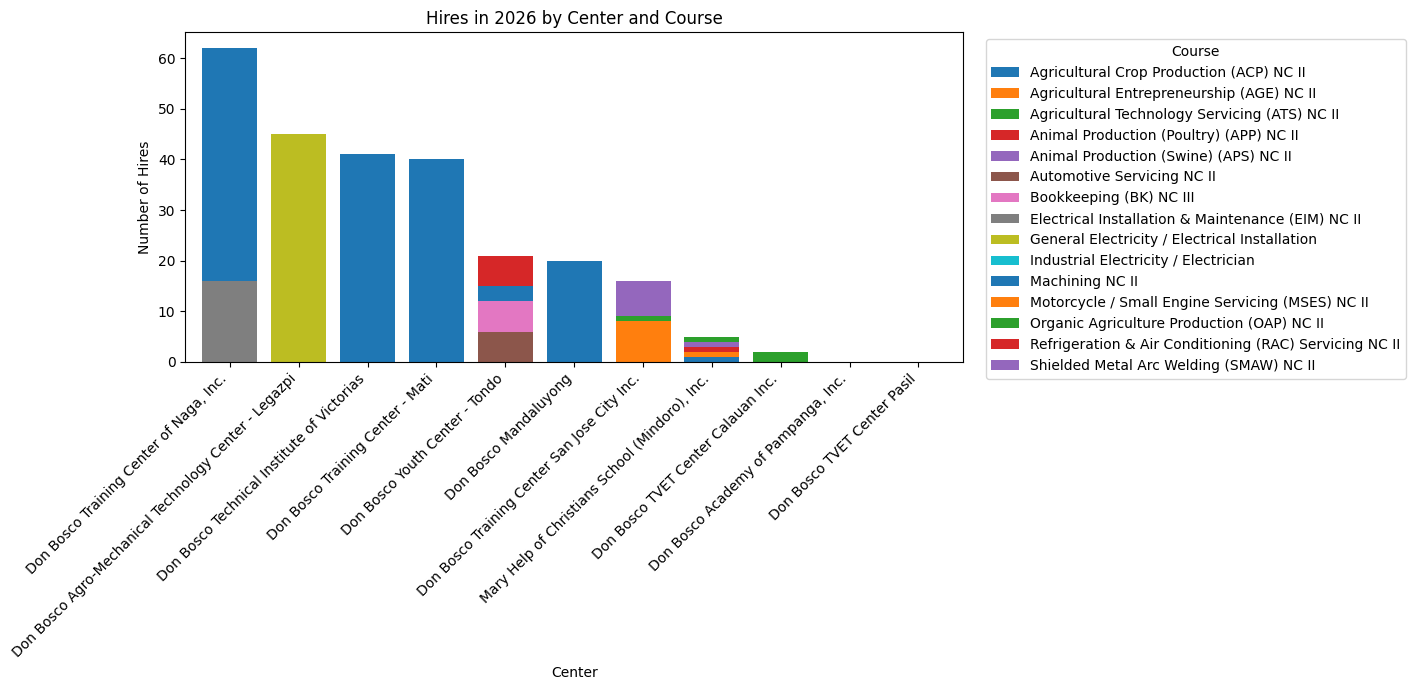

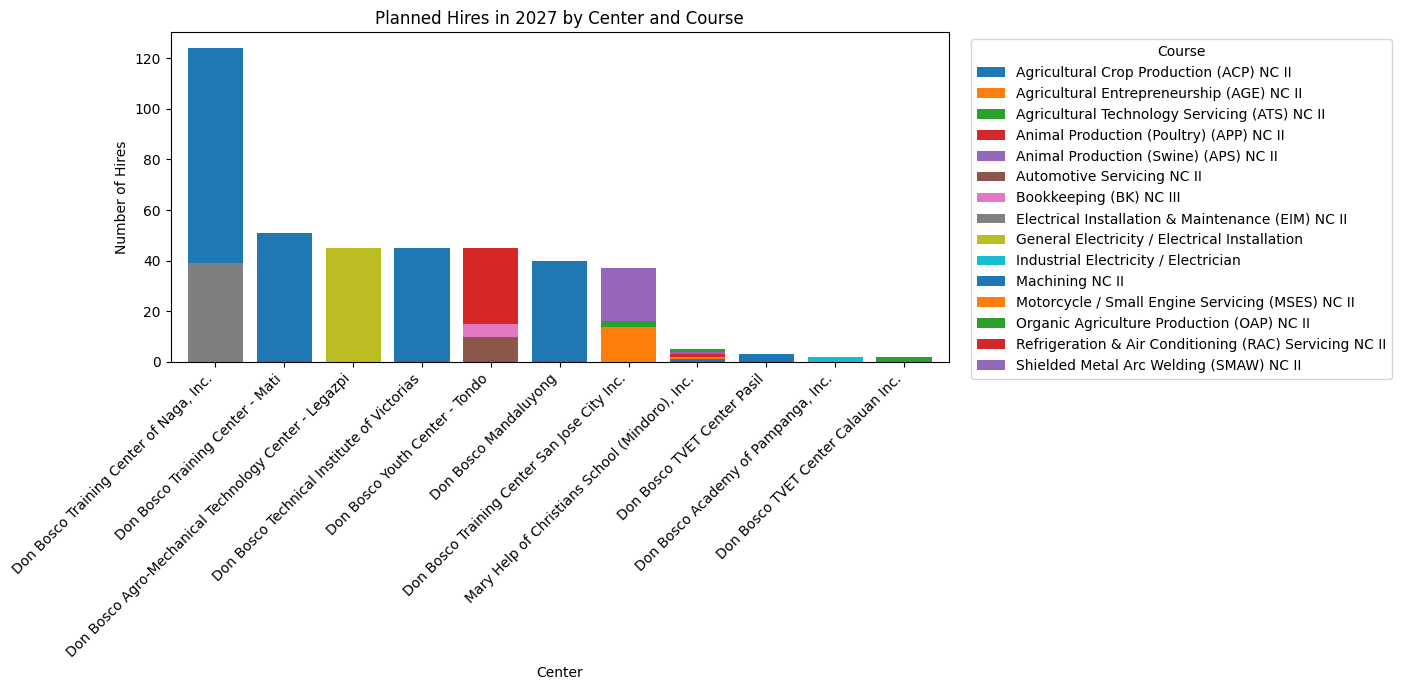

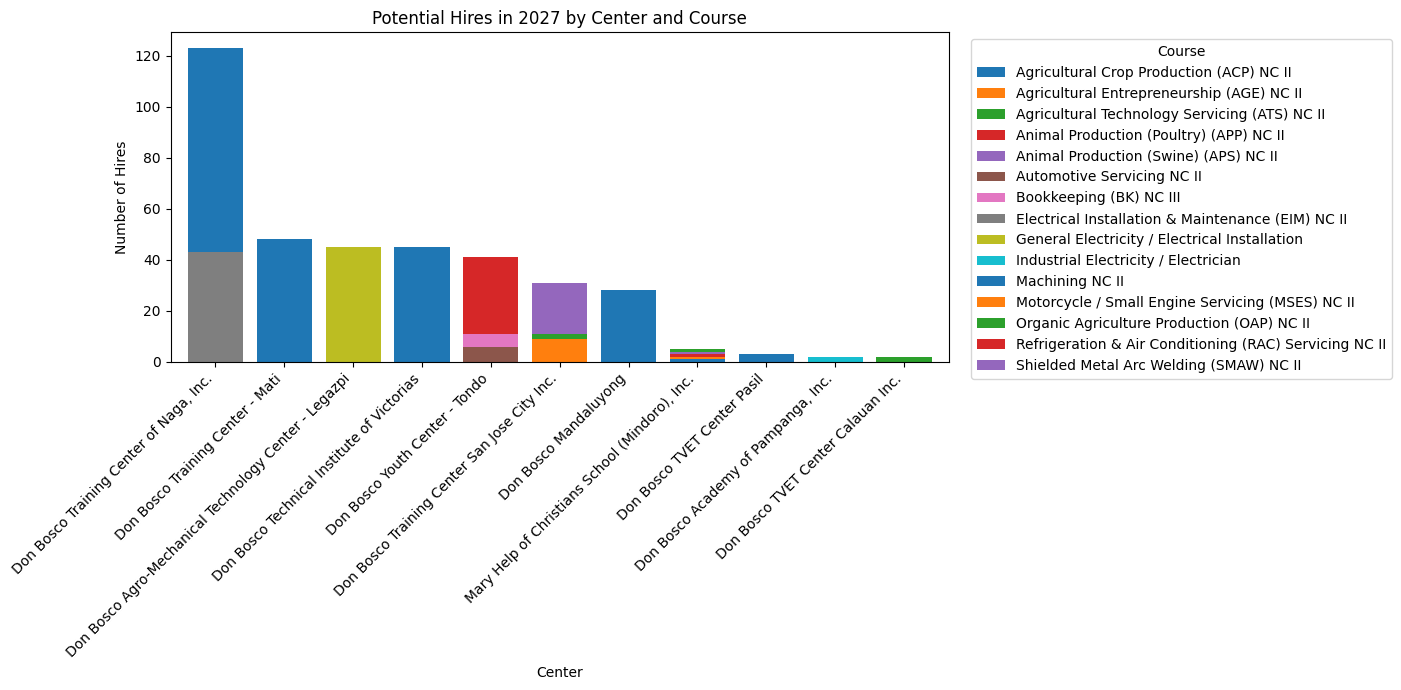

In [51]:
import matplotlib.pyplot as plt

hiring_metrics = {
    "hires_2026": "Hires in 2026",
    "planned_hires_2027": "Planned Hires in 2027",
    "potential_hires_2027": "Potential Hires in 2027",
}

# Aggregate hiring figures by center and course
center_course_hiring = (
    hiring_df.groupby(["center", "course"])[
        list(hiring_metrics.keys())
    ]
    .sum()
    .fillna(0)
)

# Create three stacked bar charts
for column, title in hiring_metrics.items():
    chart_data = center_course_hiring[column].unstack(
        "course",
        fill_value=0,
    )

    chart_data = chart_data.loc[
        chart_data.sum(axis=1).sort_values(ascending=False).index
    ]

    ax = chart_data.plot(
        kind="bar",
        stacked=True,
        figsize=(14, 7),
        width=0.8,
    )

    ax.set_title(f"{title} by Center and Course")
    ax.set_xlabel("Center")
    ax.set_ylabel("Number of Hires")
    ax.legend(
        title="Course",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [44]:
hiring_df.groupby('course')[demand_qty_cols].sum().sort_values(by='hires_2026', ascending=False)

,hires_2026,planned_hires_2027,potential_hires_2027
course,,,
Machining NC II,150.0,224.0,204.0
General Electricity / Electrical Installation,45.0,45.0,45.0
Electrical Installation & Maintenance (EIM) NC II,16.0,39.0,43.0
Motorcycle / Small Engine Servicing (MSES) NC II,8.0,14.0,9.0
Shielded Metal Arc Welding (SMAW) NC II,7.0,21.0,20.0
Automotive Servicing NC II,6.0,10.0,6.0
Bookkeeping (BK) NC III,6.0,5.0,5.0
Refrigeration & Air Conditioning (RAC) Servicing NC II,6.0,30.0,30.0
Agricultural Technology Servicing (ATS) NC II,2.0,2.0,2.0


In [54]:
hiring_df.groupby('center')[demand_qty_cols].sum().sort_values(by='planned_hires_2027')

,hires_2026,planned_hires_2027,potential_hires_2027
center,,,
"Don Bosco Academy of Pampanga, Inc.",0.0,2.0,2.0
Don Bosco TVET Center Calauan Inc.,2.0,2.0,2.0
Don Bosco TVET Center Pasil,0.0,3.0,3.0
"Mary Help of Christians School (Mindoro), Inc.",5.0,5.0,5.0
Don Bosco Training Center San Jose City Inc.,16.0,37.0,31.0
Don Bosco Mandaluyong,20.0,40.0,28.0
Don Bosco Agro-Mechanical Technology Center - Legazpi,45.0,45.0,45.0
Don Bosco Technical Institute of Victorias,41.0,45.0,45.0
Don Bosco Youth Center - Tondo,21.0,45.0,41.0
